# Use Case 28 — Software Quality Insight
## Round 2: EDA and Feature Engineering

## Step 1 — Import libraries and load the five CSV files

In [1]:
from google.colab import files
uploaded = files.upload()  # Select software_quality_insight_synthetic_dataset.zip

import zipfile, os
zip_name = next(name for name in uploaded if name.lower().endswith(".zip"))
data_dir = "/content/software_quality_insight_data"
os.makedirs(data_dir, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(data_dir)

print("Files extracted:", sorted(os.listdir(data_dir)))

Saving software_quality_insight_synthetic_dataset.zip to software_quality_insight_synthetic_dataset.zip
Files extracted: ['commits.csv', 'defects.csv', 'metrics.csv', 'modules.csv', 'releases.csv']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path("/content/software_quality_insight_data")

modules = pd.read_csv(DATA_DIR / "modules.csv")
metrics = pd.read_csv(DATA_DIR / "metrics.csv")
defects = pd.read_csv(DATA_DIR / "defects.csv")
commits = pd.read_csv(DATA_DIR / "commits.csv")
releases = pd.read_csv(DATA_DIR / "releases.csv")

datasets = {
    "modules": modules,
    "metrics": metrics,
    "defects": defects,
    "commits": commits,
    "releases": releases
}

for name, df in datasets.items():
    print(f"\n{name.upper()}: {df.shape[0]} rows × {df.shape[1]} columns")
    display(df.head(3))


MODULES: 60 rows × 4 columns


,module,component,language,size
0,MOD-001,Authentication,Python,103
1,MOD-002,Payments,C#,215
2,MOD-003,Reporting,Java,176



METRICS: 361 rows × 6 columns


,module,version,complexity,coupling,churn,test_coverage
0,MOD-001,v1.0,29.57,0.917,112,74.04
1,MOD-002,v1.0,36.66,0.552,31,48.17
2,MOD-003,v1.0,29.94,0.608,30,43.12



DEFECTS: 361 rows × 4 columns


,module,version,defect_count,severity
0,MOD-001,v1.0,1,Low
1,MOD-002,v1.0,2,Medium
2,MOD-003,v1.0,0,NaN



COMMITS: 361 rows × 5 columns


,module,version,commit_count,contributors,changed_lines
0,MOD-001,v1.0,11,2.0,134
1,MOD-002,v1.0,10,9.0,36
2,MOD-003,v1.0,13,1.0,59



RELEASES: 361 rows × 3 columns


,release_date,version,module
0,2024-01-15,v1.0,MOD-001
1,2024-01-15,v1.0,MOD-002
2,2024-01-15,v1.0,MOD-003


## Step 2 — Understand data types, missing values, duplicates and unusual values

In [3]:
for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    print(df.dtypes)
    print("\nMissing values:")
    print(df.isna().sum())
    print("Exact duplicate rows:", df.duplicated().sum())


--- MODULES ---
module       object
component    object
language     object
size          int64
dtype: object

Missing values:
module       0
component    0
language     0
size         0
dtype: int64
Exact duplicate rows: 0

--- METRICS ---
module            object
version           object
complexity       float64
coupling         float64
churn              int64
test_coverage    float64
dtype: object

Missing values:
module           0
version          0
complexity       1
coupling         1
churn            0
test_coverage    1
dtype: int64
Exact duplicate rows: 1

--- DEFECTS ---
module          object
version         object
defect_count     int64
severity        object
dtype: object

Missing values:
module            0
version           0
defect_count      0
severity        171
dtype: int64
Exact duplicate rows: 1

--- COMMITS ---
module            object
version           object
commit_count       int64
contributors     float64
changed_lines      int64
dtype: object

Missing valu

In [4]:
# Inspect numeric summaries and possible extreme values
for name, df in datasets.items():
    numeric = df.select_dtypes(include="number")
    if not numeric.empty:
        print(f"\n--- {name.upper()} numeric summary ---")
        display(numeric.describe().T)


--- MODULES numeric summary ---


,count,mean,std,min,25%,50%,75%,max
size,60.0,226.8,132.949309,80.0,128.75,201.0,291.25,725.0



--- METRICS numeric summary ---


,count,mean,std,min,25%,50%,75%,max
complexity,360.0,32.819278,52.493781,1.00,20.96500,31.215,39.9850,999.00
coupling,360.0,0.493275,0.245007,0.05,0.30675,0.516,0.7000,0.99
churn,361.0,105.196676,58.379292,0.00,60.00000,103.000,151.0000,244.00
test_coverage,360.0,66.803722,18.908941,17.90,52.66000,66.525,81.2275,100.00



--- DEFECTS numeric summary ---


,count,mean,std,min,25%,50%,75%,max
defect_count,361.0,0.861496,1.060758,0.0,0.0,1.0,1.0,5.0



--- COMMITS numeric summary ---


,count,mean,std,min,25%,50%,75%,max
commit_count,361.0,12.121884,4.278057,4.0,9.0,12.0,15.0,28.0
contributors,360.0,6.019444,3.234935,1.0,3.0,6.0,8.0,15.0
changed_lines,361.0,151.734072,86.796641,1.0,84.0,145.0,218.0,373.0


## Step 3 — Clean join keys and remove duplicate module-release rows


In [5]:
def normalize_keys(df):
    df = df.copy()
    if "module" in df.columns:
        df["module"] = df["module"].astype("string").str.strip().str.upper()
    if "version" in df.columns:
        df["version"] = df["version"].astype("string").str.strip()
    return df

modules = normalize_keys(modules)
metrics = normalize_keys(metrics)
defects = normalize_keys(defects)
commits = normalize_keys(commits)
releases = normalize_keys(releases)

releases["release_date"] = pd.to_datetime(releases["release_date"], errors="coerce")

# A module can have many releases, so module alone is not a sufficient key for these tables.
key = ["module", "version"]
for name in ["metrics", "defects", "commits", "releases"]:
    df = globals()[name]
    before = len(df)
    df = df.drop_duplicates(subset=key, keep="first")
    globals()[name] = df
    print(f"{name}: removed {before - len(df)} duplicate module-version rows")

# Module master should have one row per module
modules = modules.drop_duplicates(subset=["module"], keep="first")

known_modules = set(modules["module"].dropna())
unmatched_defects = defects.loc[~defects["module"].isin(known_modules)].copy()
print("Unmatched defect rows:", len(unmatched_defects))
display(unmatched_defects.head())

metrics: removed 2 duplicate module-version rows
defects: removed 1 duplicate module-version rows
commits: removed 2 duplicate module-version rows
releases: removed 1 duplicate module-version rows
Unmatched defect rows: 1


,module,version,defect_count,severity
44,MOD-999,v1.0,0,NaN


## Step 4 — Handle missing values and extreme complexity

In [6]:
# Numeric metric columns: convert invalid strings to missing, then median-impute
metric_numeric = ["complexity", "coupling", "churn", "test_coverage"]
for col in metric_numeric:
    metrics[col] = pd.to_numeric(metrics[col], errors="coerce")
    metrics[col] = metrics[col].fillna(metrics[col].median())

# Flag extreme complexity using the IQR rule, then cap values to the upper boundary
q1 = metrics["complexity"].quantile(0.25)
q3 = metrics["complexity"].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
metrics["complexity_outlier_flag"] = metrics["complexity"] > upper_bound
print("Complexity upper IQR boundary:", round(upper_bound, 2))
print("Extreme complexity rows flagged:", int(metrics["complexity_outlier_flag"].sum()))
metrics["complexity"] = metrics["complexity"].clip(upper=upper_bound)

# Fill missing descriptive categories
defects["severity"] = defects["severity"].fillna("Unknown")
commits["contributors"] = pd.to_numeric(commits["contributors"], errors="coerce")
commits["contributors"] = commits["contributors"].fillna(commits["contributors"].median()).round().astype(int)

# Ensure count fields are numeric
for col in ["defect_count"]:
    defects[col] = pd.to_numeric(defects[col], errors="coerce")
for col in ["commit_count", "changed_lines"]:
    commits[col] = pd.to_numeric(commits[col], errors="coerce")
    commits[col] = commits[col].fillna(commits[col].median())

print("Missing metrics after cleaning:")
display(metrics[metric_numeric].isna().sum().to_frame("missing_count"))

Complexity upper IQR boundary: 68.64
Extreme complexity rows flagged: 1
Missing metrics after cleaning:


,missing_count
complexity,0
coupling,0
churn,0
test_coverage,0


## Step 5 — Combine into one analysis table

In [7]:
analysis = releases.merge(modules, on="module", how="left", validate="many_to_one")
analysis = analysis.merge(metrics, on=["module", "version"], how="left", validate="one_to_one")
analysis = analysis.merge(defects, on=["module", "version"], how="left", validate="one_to_one")
analysis = analysis.merge(commits, on=["module", "version"], how="left", validate="one_to_one")

# Defect row absent after the join means no matching defect record in this synthetic dataset.
analysis["defect_record_missing"] = analysis["defect_count"].isna()
analysis["defect_count"] = analysis["defect_count"].fillna(0).astype(int)
analysis["severity"] = analysis["severity"].fillna("No defect record")

print("Combined table shape:", analysis.shape)
display(analysis.head())
print("Remaining missing values:")
display(analysis.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))

Combined table shape: (360, 17)


,release_date,version,module,component,language,size,complexity,coupling,churn,test_coverage,complexity_outlier_flag,defect_count,severity,commit_count,contributors,changed_lines,defect_record_missing
0,2024-01-15,v1.0,MOD-001,Authentication,Python,103,29.57,0.917,112.0,74.04,False,1,Low,11.0,2.0,134.0,False
1,2024-01-15,v1.0,MOD-002,Payments,C#,215,36.66,0.552,31.0,48.17,False,2,Medium,10.0,9.0,36.0,False
2,2024-01-15,v1.0,MOD-003,Reporting,Java,176,29.94,0.608,30.0,43.12,False,0,Unknown,13.0,1.0,59.0,False
3,2024-01-15,v1.0,MOD-004,User Interface,TypeScript,150,44.45,0.088,52.0,76.20,False,1,Medium,13.0,6.0,76.0,False
4,2024-01-15,v1.0,MOD-005,Data Access,C#,235,37.18,0.490,144.0,79.55,False,2,Low,17.0,6.0,237.0,False


Remaining missing values:


,missing_count
coupling,1
commit_count,1
churn,1
complexity,1
changed_lines,1
complexity_outlier_flag,1
contributors,1
test_coverage,1
release_date,0
size,0


## Step 6 — Descriptive analysis

In [8]:
print("Numeric summary:")
display(analysis.select_dtypes(include="number").describe().T.round(2))

print("Total defects:", int(analysis["defect_count"].sum()))
print("Module-release rows:", len(analysis))
print("Unique modules:", analysis["module"].nunique())
print("Unique releases:", analysis["version"].nunique())

module_defects = (analysis.groupby(["module", "component"], as_index=False)
                  .agg(total_defects=("defect_count", "sum"),
                       average_defects=("defect_count", "mean"),
                       releases_observed=("version", "nunique"))
                  .sort_values("total_defects", ascending=False))
display(module_defects.head(10))

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
size,360.0,226.80,132.02,80.00,128.75,201.00,291.25,725.00
complexity,359.0,30.22,12.35,1.00,20.89,31.22,39.99,68.64
coupling,359.0,0.49,0.25,0.05,0.31,0.52,0.70,0.99
churn,359.0,105.31,58.28,0.00,60.00,103.00,151.00,244.00
test_coverage,359.0,66.84,18.90,17.90,52.81,66.53,81.28,100.00
defect_count,360.0,0.86,1.06,0.00,0.00,1.00,1.00,5.00
commit_count,359.0,12.14,4.28,4.00,9.00,12.00,15.00,28.00
contributors,359.0,6.03,3.23,1.00,3.00,6.00,8.00,15.00
changed_lines,359.0,152.05,86.91,1.00,84.00,146.00,218.50,373.00


Total defects: 311
Module-release rows: 360
Unique modules: 60
Unique releases: 6


,module,component,total_defects,average_defects,releases_observed
49,MOD-050,Payments,16,2.666667,6
18,MOD-019,Authentication,13,2.166667,6
51,MOD-052,User Interface,13,2.166667,6
1,MOD-002,Payments,10,1.666667,6
57,MOD-058,User Interface,10,1.666667,6
35,MOD-036,Notifications,10,1.666667,6
26,MOD-027,Reporting,10,1.666667,6
9,MOD-010,User Interface,10,1.666667,6
22,MOD-023,Data Access,9,1.500000,6
31,MOD-032,Payments,9,1.500000,6


## Step 7 — Visualizations for the six business questions

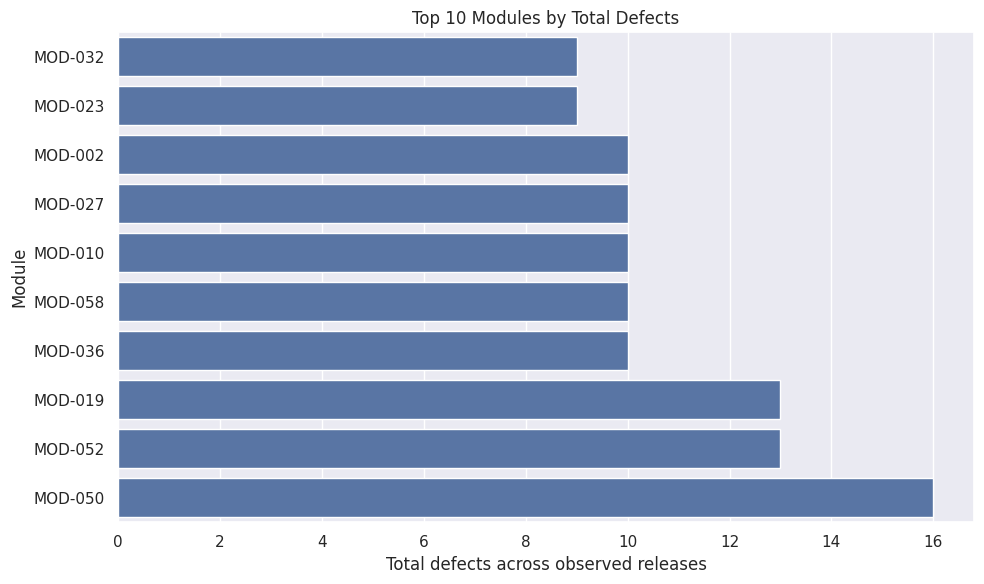

In [9]:
sns.set_theme()

# 1. Which modules have more defects?
top_modules = module_defects.head(10).sort_values("total_defects")
plt.figure(figsize=(10, 6))
sns.barplot(data=top_modules, x="total_defects", y="module")
plt.title("Top 10 Modules by Total Defects")
plt.xlabel("Total defects across observed releases")
plt.ylabel("Module")
plt.tight_layout()
plt.show()

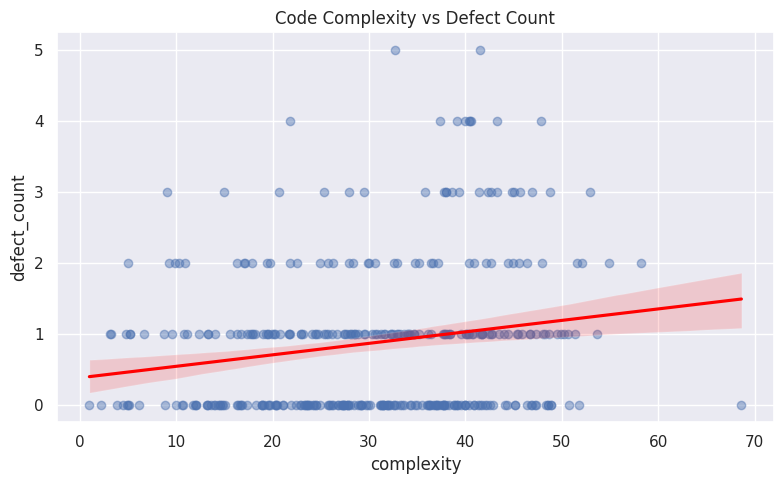

Pearson correlation: 0.188


In [10]:
# 2. How does complexity relate to defects?
plt.figure(figsize=(8, 5))
sns.regplot(data=analysis, x="complexity", y="defect_count",
            scatter_kws={"alpha": 0.45}, line_kws={"color": "red"})
plt.title("Code Complexity vs Defect Count")
plt.tight_layout()
plt.show()
print("Pearson correlation:", round(analysis["complexity"].corr(analysis["defect_count"]), 3))

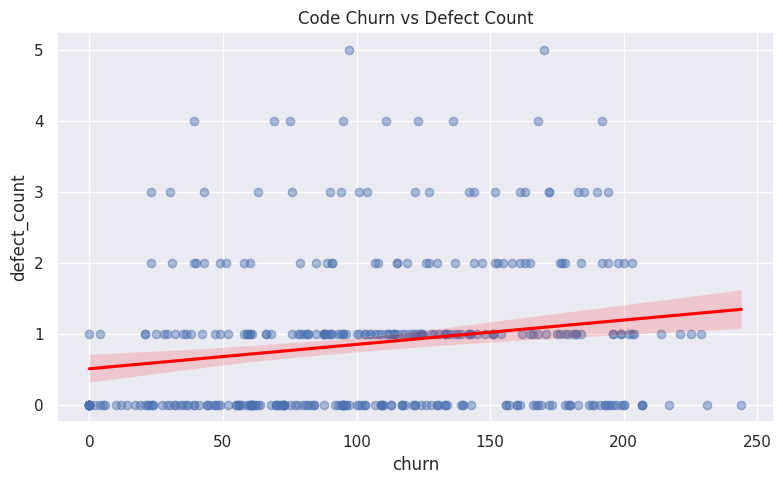

Pearson correlation: 0.188


In [11]:
# 3. Does code churn relate to quality?
plt.figure(figsize=(8, 5))
sns.regplot(data=analysis, x="churn", y="defect_count",
            scatter_kws={"alpha": 0.45}, line_kws={"color": "red"})
plt.title("Code Churn vs Defect Count")
plt.tight_layout()
plt.show()
print("Pearson correlation:", round(analysis["churn"].corr(analysis["defect_count"]), 3))

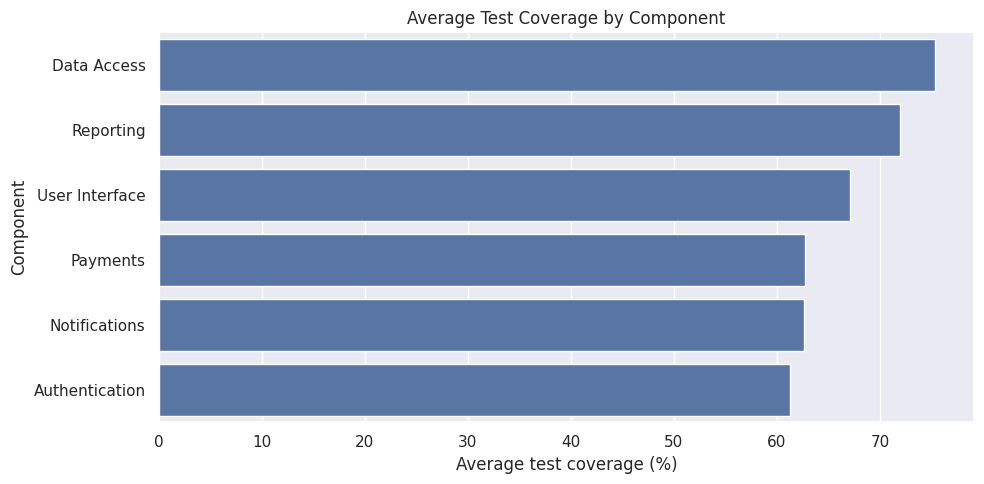

,component,mean_coverage,total_defects
1,Data Access,75.36,48
4,Reporting,71.98,53
5,User Interface,67.11,57
3,Payments,62.74,54
2,Notifications,62.66,45
0,Authentication,61.25,54


In [12]:
# 4. How does test coverage differ?
coverage_by_component = (analysis.groupby("component", as_index=False)
                         .agg(mean_coverage=("test_coverage", "mean"),
                              total_defects=("defect_count", "sum"))
                         .sort_values("mean_coverage", ascending=False))
plt.figure(figsize=(10, 5))
sns.barplot(data=coverage_by_component, x="mean_coverage", y="component")
plt.title("Average Test Coverage by Component")
plt.xlabel("Average test coverage (%)")
plt.ylabel("Component")
plt.tight_layout()
plt.show()
display(coverage_by_component.round(2))

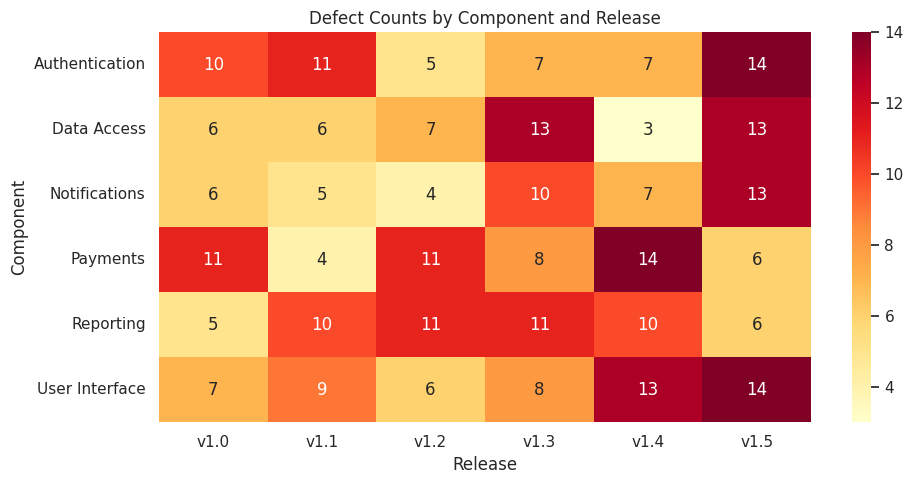

In [13]:
# 5. Which components show repeated defects across releases?
component_release = (analysis.groupby(["component", "version"], as_index=False)
                     .agg(defects=("defect_count", "sum")))
pivot = component_release.pivot(index="component", columns="version", values="defects").fillna(0)
plt.figure(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Defect Counts by Component and Release")
plt.xlabel("Release")
plt.ylabel("Component")
plt.tight_layout()
plt.show()

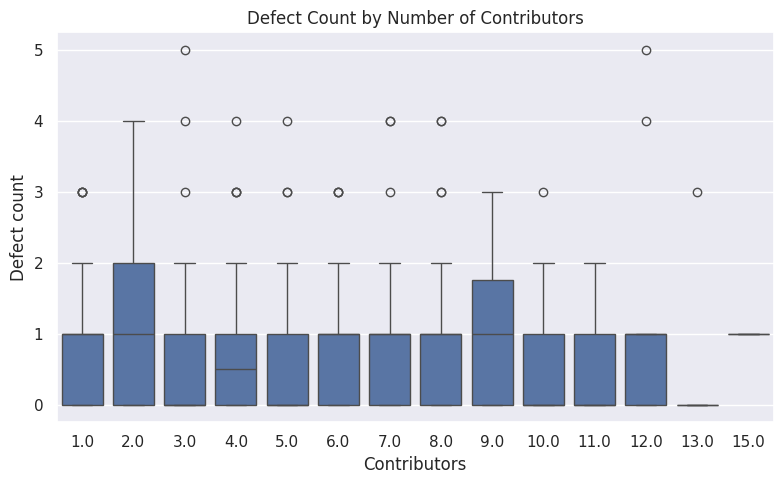

Contributor/defect correlation: -0.034


In [14]:
# 6. Does contributor count relate to defect frequency?
plt.figure(figsize=(8, 5))
sns.boxplot(data=analysis, x="contributors", y="defect_count")
plt.title("Defect Count by Number of Contributors")
plt.xlabel("Contributors")
plt.ylabel("Defect count")
plt.tight_layout()
plt.show()
print("Contributor/defect correlation:",
      round(analysis["contributors"].corr(analysis["defect_count"]), 3))

## Step 8 — Additional relationships and release trends

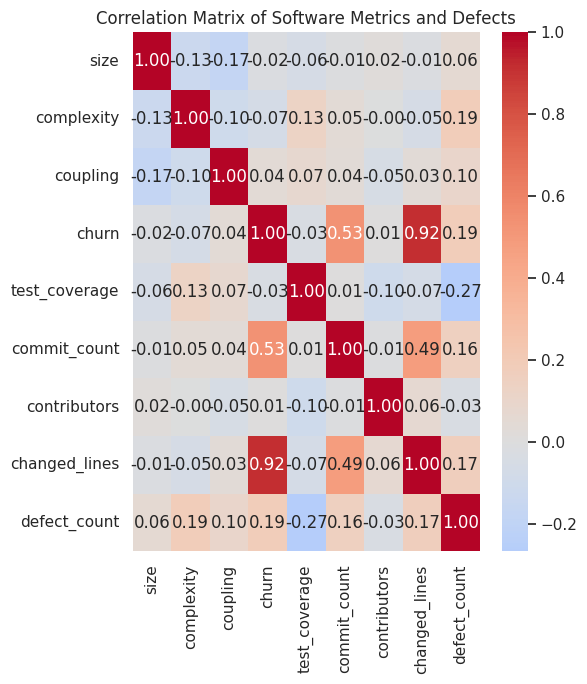

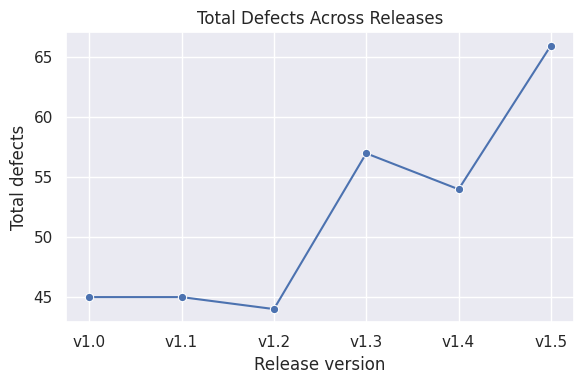

,version,release_date,defect_count
0,v1.0,2024-01-15,45
1,v1.1,2024-04-14,45
2,v1.2,2024-07-13,44
3,v1.3,2024-10-11,57
4,v1.4,2025-01-09,54
5,v1.5,2025-04-09,66


In [15]:
# Correlation matrix for numeric variables
numeric_cols = ["size", "complexity", "coupling", "churn", "test_coverage",
                "commit_count", "contributors", "changed_lines", "defect_count"]
plt.figure(figsize=(6, 7))
sns.heatmap(analysis[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Software Metrics and Defects")
plt.tight_layout()
plt.show()

print("\n")
# Total defects by release
release_trend = analysis.groupby(["version", "release_date"], as_index=False)["defect_count"].sum()
release_trend = release_trend.sort_values("release_date")
plt.figure(figsize=(6, 4))
sns.lineplot(data=release_trend, x="version", y="defect_count", marker="o")
plt.title("Total Defects Across Releases")
plt.xlabel("Release version")
plt.ylabel("Total defects")
plt.tight_layout()
plt.show()
display(release_trend)

## Step 9 — Feature engineering

These features express the original data in a more interpretable way:
- `defects_per_1000_lines`: defect count scaled by module size (a descriptive feature; do not use it to predict defect count because it directly includes the target).
- `churn_per_kloc`: changed lines relative to module size.
- `complexity_band`: low, medium or high complexity.
- `low_coverage_flag`: identifies coverage below 60%.
- `release_month` and `release_quarter`: time features.
- One-hot encoding: converts component, language and severity categories into numeric indicator columns.

For feature selection to predict defect count, we deliberately exclude `defects_per_1000_lines` and `severity` because they are derived from or closely tied to defect outcomes and could cause target leakage.

In [16]:
analysis["defects_per_1000_lines"] = analysis["defect_count"] / (analysis["size"].clip(lower=1) / 1000)
analysis["churn_per_kloc"] = analysis["changed_lines"] / (analysis["size"].clip(lower=1) / 1000)
analysis["complexity_band"] = pd.cut(
    analysis["complexity"],
    bins=[-np.inf, 20, 40, np.inf],
    labels=["Low", "Medium", "High"]
)
analysis["low_coverage_flag"] = (analysis["test_coverage"] < 60).astype(int)
analysis["release_month"] = analysis["release_date"].dt.month
analysis["release_quarter"] = analysis["release_date"].dt.quarter

display(analysis[["module", "version", "defect_count", "defects_per_1000_lines",
                  "churn_per_kloc", "complexity_band", "low_coverage_flag",
                  "release_month", "release_quarter"]].head(10))

,module,version,defect_count,defects_per_1000_lines,churn_per_kloc,complexity_band,low_coverage_flag,release_month,release_quarter
0,MOD-001,v1.0,1,9.708738,1300.970874,Medium,0,1,1
1,MOD-002,v1.0,2,9.302326,167.441860,Medium,1,1,1
2,MOD-003,v1.0,0,0.000000,335.227273,Medium,1,1,1
3,MOD-004,v1.0,1,6.666667,506.666667,High,0,1,1
4,MOD-005,v1.0,2,8.510638,1008.510638,Medium,0,1,1
5,MOD-006,v1.0,3,9.009009,687.687688,Medium,1,1,1
6,MOD-007,v1.0,1,5.025126,964.824121,Low,1,1,1
7,MOD-008,v1.0,3,28.846154,1403.846154,Low,0,1,1
8,MOD-009,v1.0,0,0.000000,484.000000,Low,0,1,1
9,MOD-010,v1.0,4,25.806452,1561.290323,Medium,0,1,1


## Step 10 — Encode categorical variables and select relevant features

We use a simple train/test split and a Random Forest regressor as a feature-importance aid, not as a required prediction model. The assessment asks for feature selection where appropriate; interpret feature importance as association, not causation. Since this dataset is synthetic, importance rankings are only for practice.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target = "defect_count"
exclude = {
    target, "severity", "defects_per_1000_lines", "defect_record_missing",
    "release_date", "module", "version", "complexity_outlier_flag"
}
feature_cols = [c for c in analysis.columns if c not in exclude]

X = analysis[feature_cols].copy()
y = analysis[target].copy()

# Convert date-derived and categorical fields safely; remove raw datetime if present.
X = X.drop(columns=["release_date"], errors="ignore")
cat_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]), num_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=28
)

feature_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=250, random_state=28, min_samples_leaf=2))
])
feature_model.fit(X_train, y_train)
pred = feature_model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
print("R²:", round(r2_score(y_test, pred), 3))

MAE: 0.781
RMSE: 0.993
R²: 0.134


,feature,importance
4,numeric__test_coverage,0.203037
1,numeric__complexity,0.169794
2,numeric__coupling,0.092729
5,numeric__commit_count,0.078013
3,numeric__churn,0.076904
6,numeric__contributors,0.070477
7,numeric__changed_lines,0.067953
0,numeric__size,0.065903
8,numeric__churn_per_kloc,0.059063
10,numeric__release_month,0.016946


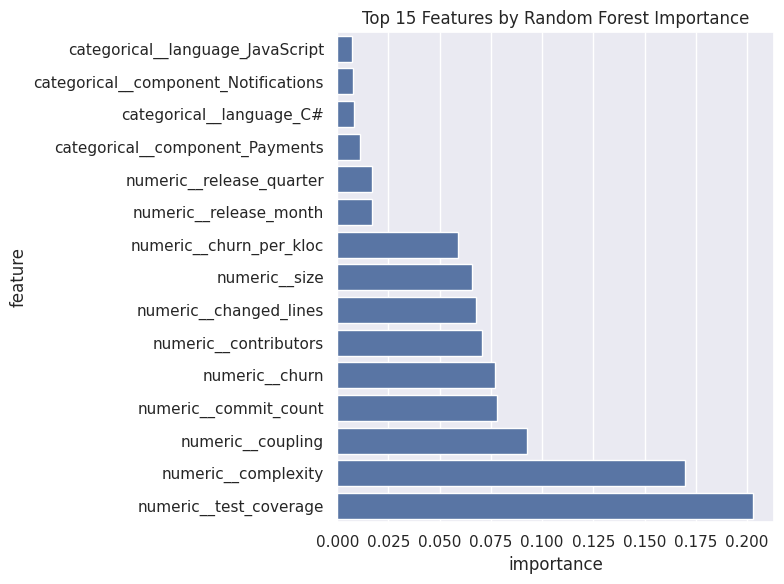

In [18]:
# Extract feature names after one-hot encoding and rank feature importances
feature_names = feature_model.named_steps["preprocessor"].get_feature_names_out()
importances = feature_model.named_steps["model"].feature_importances_
importance_df = (pd.DataFrame({"feature": feature_names, "importance": importances})
                 .sort_values("importance", ascending=False))
display(importance_df.head(15))
print("\n")

top_importance = importance_df.head(15).sort_values("importance")
plt.figure(figsize=(8, 6))
sns.barplot(data=top_importance, x="importance", y="feature")
plt.title("Top 15 Features by Random Forest Importance")
plt.tight_layout()
plt.show()

## Step 11 — Summarize evidence-based findings

Run this after the charts. It generates data-specific summary values from the synthetic data. Use the actual outputs, not guessed numbers, in your report.

In [19]:
print("ROUND 2 SUMMARY")
print("=" * 50)
print(f"Module-release rows analyzed: {len(analysis)}")
print(f"Unique modules: {analysis['module'].nunique()}")
print(f"Releases: {analysis['version'].nunique()}")
print(f"Total defects in joined table: {analysis['defect_count'].sum()}")
print(f"Unmatched defect rows before join: {len(unmatched_defects)}")
print(f"Complexity outliers flagged: {int(metrics['complexity_outlier_flag'].sum()) if 'complexity_outlier_flag' in metrics else 'see Step 4 output'}")

print("\nTop 5 modules by total defects:")
display(module_defects.head(5))

print("\nCorrelations with defect count:")
display(analysis[["complexity", "coupling", "churn", "test_coverage",
                  "commit_count", "contributors", "changed_lines", "defect_count"]]
        .corr(numeric_only=True)["defect_count"].sort_values(ascending=False).to_frame("correlation"))

print("\nAverage test coverage by component:")
display(coverage_by_component.round(2))

ROUND 2 SUMMARY
Module-release rows analyzed: 360
Unique modules: 60
Releases: 6
Total defects in joined table: 311
Unmatched defect rows before join: 1
Complexity outliers flagged: 1

Top 5 modules by total defects:


,module,component,total_defects,average_defects,releases_observed
49,MOD-050,Payments,16,2.666667,6
18,MOD-019,Authentication,13,2.166667,6
51,MOD-052,User Interface,13,2.166667,6
1,MOD-002,Payments,10,1.666667,6
57,MOD-058,User Interface,10,1.666667,6



Correlations with defect count:


,correlation
defect_count,1.000000
churn,0.188496
complexity,0.188230
changed_lines,0.171518
commit_count,0.155305
coupling,0.097021
contributors,-0.033744
test_coverage,-0.266705



Average test coverage by component:


,component,mean_coverage,total_defects
1,Data Access,75.36,48
4,Reporting,71.98,53
5,User Interface,67.11,57
3,Payments,62.74,54
2,Notifications,62.66,45
0,Authentication,61.25,54


## Step 12 — Export deliverables

This saves the cleaned joined dataset, unmatched defect records, engineered dataset, and feature importance table. Download them from Colab for Round 3.

In [20]:
import os
from google.colab import files

# Create output folder
output_dir = "/content/round2_outputs"
os.makedirs(output_dir, exist_ok=True)

# Save cleaned dataset with your preferred filename
cleaned_file = f"{output_dir}/cleaned dataset.csv"
analysis.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print("File path:", cleaned_file)
print("Rows and columns:", analysis.shape)

# Download the cleaned dataset
files.download(cleaned_file)


Cleaned dataset saved successfully!
File path: /content/round2_outputs/cleaned dataset.csv
Rows and columns: (360, 23)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# 2. Save unmatched defect records
unmatched_defects.to_csv(
    f"{output_dir}/unmatched_defect_records.csv",
    index=False
)

In [22]:
importance_df.to_csv(
    f"{output_dir}/feature_importance.csv", index=False
)
module_defects.to_csv(
    f"{output_dir}/module_defect_summary.csv", index=False
)
coverage_by_component.to_csv(
    f"{output_dir}/component_coverage_summary.csv", index=False
)

In [23]:
print("Files saved:")
print("\n".join(sorted(os.listdir(output_dir))))

Files saved:
cleaned dataset.csv
component_coverage_summary.csv
feature_importance.csv
module_defect_summary.csv
unmatched_defect_records.csv


In [24]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/Round2_Software_Quality_Insight",
    "zip",
    "/content/round2_outputs"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>